# Estacionalidad en series temporales

In [ ]:
#pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
    ----------------

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics import tsaplots
from statsmodels.graphics.tsaplots import plot_acf


## 1. Lectura de datos

Leer, mediante pandas, los datos contenidos en "daily_min-temperatures.csv".

In [ ]:
df = pd.read_csv("daily-min-temperatures.csv", header = 0) 
df.head()

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


In [5]:
print(df)

            Date  Temp
0     1981-01-01  20.7
1     1981-01-02  17.9
2     1981-01-03  18.8
3     1981-01-04  14.6
4     1981-01-05  15.8
...          ...   ...
3645  1990-12-27  14.0
3646  1990-12-28  13.6
3647  1990-12-29  13.5
3648  1990-12-30  15.7
3649  1990-12-31  13.0

[3650 rows x 2 columns]


## 2. Formato de columnas

Compueba el formato de las columnas y cámbialo si es necesario.

In [5]:
df.dtypes

Date     object
Temp    float64
dtype: object

## 3. Visualización de la serie


<Axes: >

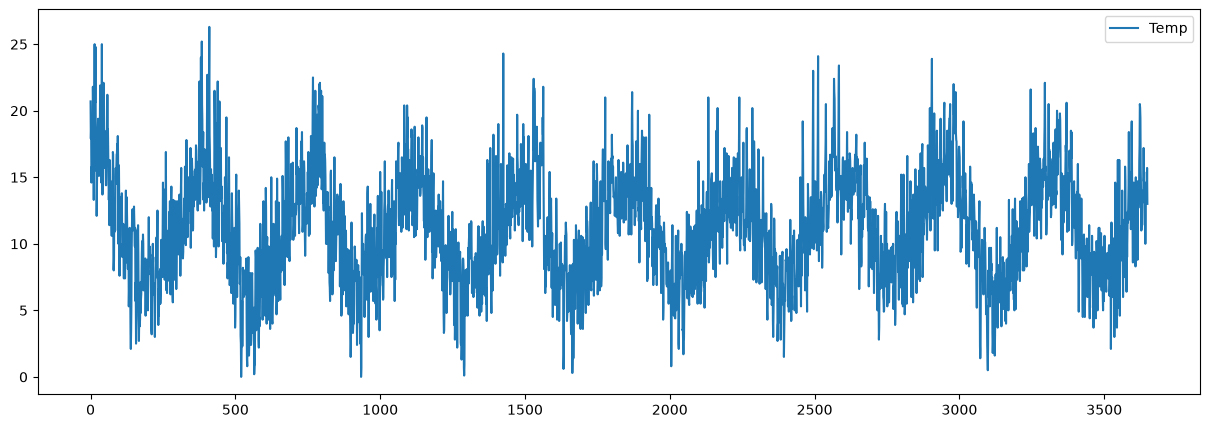

In [6]:
df.plot(figsize=(15,5))

## 4. Obtención y eliminación de la estacionalidad

### 4.1 Comprobación mediante función de autocorrelación


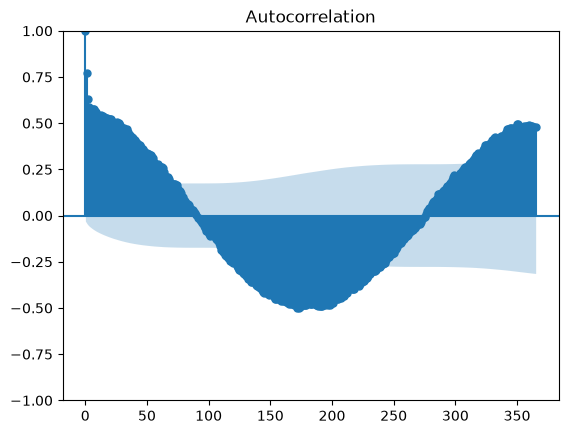

In [ ]:
plot_acf(df["Temp"].dropna(), lags=365) #como va por año lags 365 por dias de un año
plt.show()

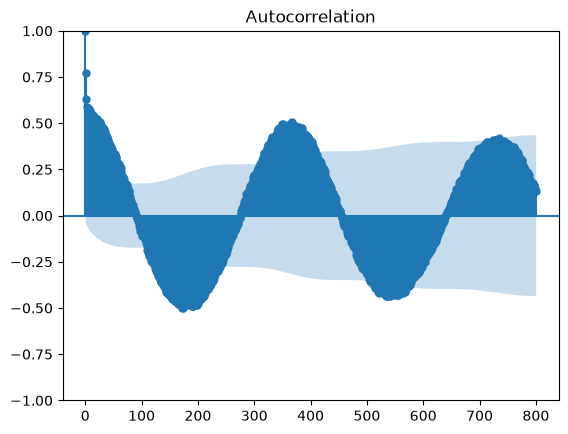

In [8]:
plot_acf(df["Temp"].dropna(), lags=800) #probar
plt.show()

### 4.2 Mediante la media móvil

<Axes: >

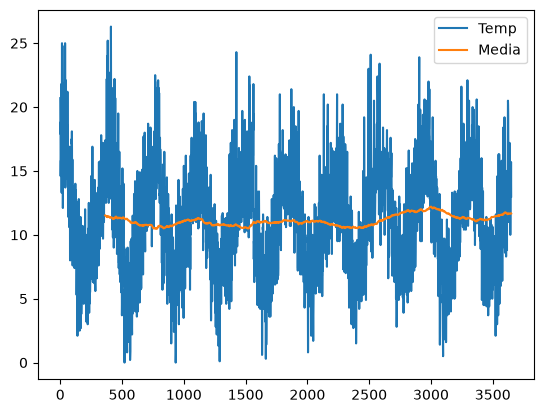

In [ ]:
df['Media'] = df["Temp"].rolling(window=365).mean() 
df[["Temp", "Media"]].plot()

### 4.3 Seasonal Decompose

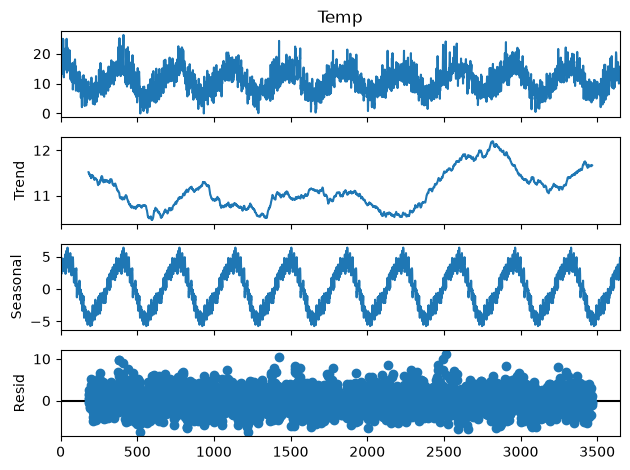

In [ ]:
descomposicion = seasonal_decompose(df["Temp"], model="additive", period=365) #hay que poner un periodo en el que la tendencia no se repita

descomposicion.plot()
plt.show()

### 4.4 Diff

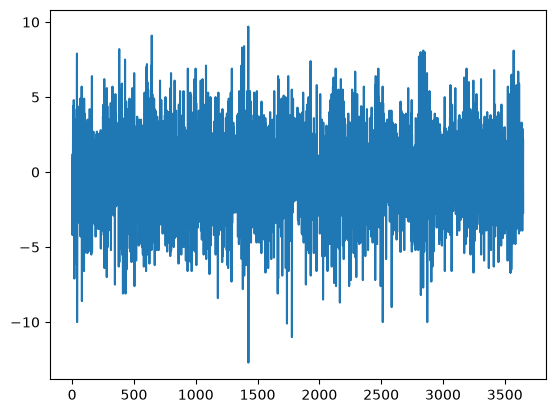

In [15]:
df['Temp_diff'] = df['Temp'].diff()
df['Temp_diff'] .plot()
plt.show()